In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.7 メモリマップの確認 (`osbook_day02b`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.7_Analyzing_Memory_Map_Output.ipynb)

本節では、名著『ゼロからのOS自作入門』第2章「EDK II入門とメモリマップ」の **2.7「メモリマップの確認」**（対応タグ: `osbook_day02b`）を徹底解説します。

前節（2.6節）では、UEFI のオブジェクト指向プロトコルモデル（`EFI_LOADED_IMAGE_PROTOCOL`, `EFI_SIMPLE_FILE_SYSTEM_PROTOCOL`, `EFI_FILE_PROTOCOL`）を利用して、取得したメモリマップをディスク上の `\memmap` という CSV 形式のファイルへ書き出すプログラムを実装しました。

本節では、出力された `memmap` ファイルの具体的な内容を詳しく観察・解析します。
- **「PCに搭載された物理RAM容量」と「OSが実際に利用可能なRAM容量」の決定的な違い**
- **16種類のメモリタイプ（`EFI_MEMORY_TYPE`）の分類と、OSブート完了（`ExitBootServices()`）後に回収可能なメモリ領域**
- **物理アドレス空間がなぜ細かくバラバラに分断（断片化 / Fragmentation）されているのか**
- **第3章のブートローダによるカーネル配置、および第8章のビットマップメモリマネージャ（`BitmapMemoryManager`）への接続**

これらを、数理計算、Mermaidダイアグラム、高解像度可視化プロット、Pythonシミュレータ、および C++20 検証コードを通じて完全自己完結で解き明かします。


## 2.7.1 なぜメモリマップを詳細に確認するのか？（OS開発者視点での動機と課題）

一般のアプリケーションプログラマであれば、「メモリを 16GB 搭載したPCなら、16GB 自由に使える」と考えがちです。しかし、ベアメタル（Bare-metal: OSが存在しない生ハードウェア）で動作する OS 開発者にとっては、この認識は**極めて致命的なクラッシュ**を引き起こします。

```mermaid
flowchart TD
    subgraph Hardware["物理ハードウェア (Physical Hardware)"]
        RAM["物理 RAM チップ (DRAM 2GiB)"]
        MMIO["PCI / APIC / マザーボード MMIO"]
        ROM["SPI Flash ROM (UEFI BIOS ファームウェア)"]
    end

    subgraph Problem["OS開発者が直面する物理メモリの現実"]
        Hole["MMIO ホール (3.5GiB〜4GiB 付近): RAMではない"]
        Firmware["UEFI 予約領域 (ファームウェア実行コード・スタック)"]
        Legacy["0x0〜1MiB レガシー予約 (IVT, BDA, EBDA, VRAM)"]
        Frag["断片化 (Fragmentation): 空きRAMが一続きではない"]
    end

    Hardware --> Problem
    Problem --> Solution["メモリマップ解析 (Memory Map Analysis) による空き領域の厳密特定"]
```

### OSが直面する3つの壁
1. **メモリマップド I/O（MMIO: *Memory-Mapped I/O*）との衝突回避**:
   - PCI デバイスの制御レジスタやローカル APIC、グラフィックスカードの VRAM などは、物理アドレス空間の一部にマッピングされています。OS が「空き RAM だ」と誤認してこれらの領域に汎用データを上書きすると、ハードウェアが誤動作したり PC が即座にリセット（Triple Fault）します。
2. **UEFI ファームウェア自身が使用している作業領域の保護**:
   - ブートローダ実行中はもちろん、OS 起動後もマザーボードの電源管理（ACPI: *Advanced Configuration and Power Interface*）やシステム時刻・NVRAM 変更などを行う UEFI ランタイムサービス（Runtime Services）領域は、決して上書きしてはなりません。
3. **カーネルのロード先と動的メモリ管理の開始地点の決定**:
   - 次章（第3章）では、ブートローダが MikanOS カーネル（`kernel.elf`）をディスクから読み込んでメモリ上に配置します。**「安全にカーネルを展開できる連続した空き物理メモリはどこにあるのか？」** を知るには、メモリマップの完全な把握が絶対に不可欠です。


## 2.7.2 メモリマップ CSV のフォーマット仕様と各列の意味

前節で実装した `SaveMemoryMap()` 関数が出力した `\memmap` ファイルの1行1行は、UEFI 仕様書で定められた `EFI_MEMORY_DESCRIPTOR` 構造体の内容を人間およびプログラムが読み取れるように整形したものです。

```csv
Index, Type, Type(name), PhysicalStart, NumberOfPages, Attribute
0, 0, EfiReservedMemoryType, 00000000, 1, f
1, 7, EfiConventionalMemory, 00001000, 9f, f
2, 0, EfiReservedMemoryType, 000a0000, 60, f
3, 7, EfiConventionalMemory, 00100000, 7ef00, f
4, 3, EfiBootServicesCode, 7f000000, 1000, f
...
```

| カラム名 | 書式 / 進数 | C型定義 | 説明・OSにとっての意義 |
|:---|:---:|:---|:---|
| **`Index`** | 10進数 (`%u`) | `UINTN` | ディスクリプタの通し番号 ($0, 1, 2, \dots$)。QEMU OVMF 環境では通常 30〜60 個、実機 PC では 100〜200 個程度存在します。 |
| **`Type`** | 16進数 (`%x`) | `EFI_MEMORY_TYPE` | メモリタイプの数値コード（$0 \sim 15$）。後述の分類に使用。 |
| **`Type(name)`** | 文字列 (`%-ls`) | `const CHAR16*` | メモリタイプの英語名称（例: `EfiConventionalMemory`, `EfiBootServicesData`）。 |
| **`PhysicalStart`** | 16進数 8/16桁 (`%08lx`) | `EFI_PHYSICAL_ADDRESS` | 当該メモリ領域の**物理開始アドレス**（バイト単位）。必ず 4096 バイト（4KiB）境界にアライメント（整列）されています。 |
| **`NumberOfPages`** | 16進数 (`%lx`) | `UINT64` | 当該領域に含まれる **4KiB ページ数**。 |
| **`Attribute`** | 16進数 (`%lx`) | `UINT64` | メモリのキャッシュ属性・保護属性フラグ（下位20ビットマスク: `& 0xffffflu`）。`0xf` は UC/WC/WT/WB 全属性をサポートしていることを意味します。 |

### 物理アドレスと容量の数理計算
UEFI における 1 ページは、x86-64 アーキテクチャの標準ページサイズである **$4096$ バイト（$4	ext{KiB} = 2^{12}	ext{ bytes}$）** と定義されています。

したがって、各ディスクリプタが表すバイト容量 $	ext{SizeBytes}$ および終端物理アドレス $	ext{PhysicalEnd}$ は以下の式で厳密に計算されます：

$$	ext{SizeBytes} = 	ext{NumberOfPages} 	imes 4096 = 	ext{NumberOfPages} 	imes 2^{12} = 	ext{NumberOfPages} \ll 12$$

$$	ext{PhysicalEnd} = 	ext{PhysicalStart} + 	ext{SizeBytes} = 	ext{PhysicalStart} + (	ext{NumberOfPages} \ll 12)$$

例えば、Index 3 のエントリ：
$$	ext{PhysicalStart} = \mathtt{0x00100000}\ (1	ext{MiB}),\quad 	ext{NumberOfPages} = \mathtt{0x7ef00}\ (519,936	ext{ ページ})$$
$$	ext{SizeBytes} = 519,936 	imes 4,096 = 2,129,657,856	ext{ バイト} pprox 2,031.0	ext{ MiB} pprox 1.98	ext{ GiB}$$
$$	ext{PhysicalEnd} = \mathtt{0x00100000} + \mathtt{0x7ef00000} = \mathtt{0x7f000000}$$

この計算により、物理アドレス `0x00100000` から `0x7f000000` の手前までの約 2GiB の広大な領域が、すべて自由に使用できる RAM であることが一目で分かります。


## 2.7.3 各メモリタイプ（`EFI_MEMORY_TYPE`）の分類とOSにとってのライフサイクル

UEFI 仕様書（UEFI Specification Version 2.8+ Table 7-5）には、16種類のメモリタイプが定義されています。OS開発者にとって最も重要なのは、**「この領域は今使えるのか？ 後で使えるのか？ それとも絶対に触ってはいけないのか？」** というライフサイクル分類です。

```mermaid
flowchart TD
    subgraph AllMemory["UEFI メモリ領域 (All Memory Descriptors)"]
        UsableNow["即時利用可能 (Type 7: EfiConventionalMemory)"]
        Reclaimable["OS起動後に回収可能 (Boot Services 領域)"]
        Preserved["永続保護・ファームウェア (Runtime / ACPI)"]
        HardwareArea["ハードウェア・I/O領域 (MMIO / Reserved)"]
    end

    subgraph Lifecycle["OS ライフサイクルにおける挙動"]
        Reclaimable -->|"ExitBootServices() 呼び出し後"| Merged["OSの空きRAMプールへ統合回収！"]
        UsableNow -->|"ブート中から"| KernelHeap["ブートローダ・カーネル本体・初期スタック配置"]
        Preserved -->|"OS稼働中も保護"| KeepForever["ACPI電源制御・時刻設定のためにOSページテーブルへ恒等マッピング"]
        HardwareArea -->|"書き込み厳禁"| NoTouch["デバイスドライバ制御用MMIOとして個別マッピング"]
    end
```

### メモリタイプの3大カテゴリ

#### カテゴリ A: OS が RAM として自由に使用できる領域（Free RAM Pool）
1. **`EfiConventionalMemory` (Type 7)**:
   - **通常の空き物理 RAM**。プログラムやデータ、スタック、ヒープなど、OS が何に使っても全く問題のない自由領域です。
2. **`EfiBootServicesCode` (Type 3) & `EfiBootServicesData` (Type 4)**:
   - UEFI ファームウェアがブートローダ（`BOOTX64.EFI`）を実行するために確保したコード・データ領域。
   - **超重要**: ブートローダが最後に `gBS->ExitBootServices()` を呼び出して UEFI から制御を完全に離脱した瞬間、この領域は**ファームウェアには二度と必要なくなります**。したがって、OS はこの領域を `EfiConventionalMemory` と同様の空き RAM として回収・再利用（Reclaim）できます！
3. **`EfiLoaderCode` (Type 1) & `EfiLoaderData` (Type 2)**:
   - ブートローダ自身（`BOOTX64.EFI`）が配置されているメモリ。カーネルに処理が完全に移り、ブートローダが不要になればこれも再利用可能です。

#### カテゴリ B: OS が稼働中も絶対に保護しなければならない領域（Preserved Firmware & ACPI）
1. **`EfiRuntimeServicesCode` (Type 5) & `EfiRuntimeServicesData` (Type 6)**:
   - OS 起動後も UEFI ランタイムサービス（システム時刻の取得、NVRAM 変数の読み書き、`ResetSystem()` によるシャットダウン等）を呼び出すために常駐させておく必要がある領域。OS はここを絶対に上書きしてはなりません。
2. **`EfiACPIReclaimMemory` (Type 9) & `EfiACPIMemoryNVS` (Type 10)**:
   - ACPI テーブル（RSDP, XSDT, FADT, MADT 等）が格納されている領域。第11章でタイマ周波数較正やマルチプロセッサ初期化を行う際に OS が読み出します。ReclaimMemory はテーブル読み取り完了後に解放可能ですが、MemoryNVS (Non-Volatile Storage) は休止状態（Hibernate）復帰等のために永続保持が必須です。

#### カテゴリ C: ハードウェアおよび予約領域（Hardware & Reserved）
1. **`EfiReservedMemoryType` (Type 0)**:
   - プラットフォーム（マザーボード等）固有のファームウェア予約領域。OS は使用禁止。
2. **`EfiMemoryMappedIO` (Type 11) & `EfiMemoryMappedIOPortSpace` (Type 12)**:
   - PCI デバイスや Local APIC、I/O APIC 等の MMIO 領域。RAM ではないため、通常のメモリ確保対象にしてはなりません。
3. **`EfiUnusableMemory` (Type 8)**:
   - メモリテスト等でハードウェア的なパリティエラーや破損が検出された不良 RAM 領域。


## 2.7.4 メモリマップの統計分析：利用可能 RAM と回収可能プールの数理導出

メモリマップ全体を走査して各カテゴリの容量を集計する数式を導出します。

### 1. 即時空き物理 RAM 容量（Conventional Memory）
ブートローダ実行中から即座に利用できる物理 RAM の合計バイト数 $M_{	ext{conv}}$ は、タイプが `EfiConventionalMemory`（Type 7）であるすべてのディスクリプタ $r \in \mathcal{D}_{	ext{conv}}$ のページ数の総和に 4096 を乗じたものです：

$$M_{	ext{conv}} = \sum_{r \in \mathcal{D}_{	ext{conv}}} (	ext{NumberOfPages}(r) 	imes 4096) \quad [	ext{Bytes}]$$

### 2. 回収可能メモリ容量（Reclaimable Boot Services Pool）
`ExitBootServices()` 呼び出し後に OS が追加で手に入れることができる物理 RAM 容量 $M_{	ext{reclaim}}$ は、Type 3（Code）および Type 4（Data）の総和です：

$$M_{	ext{reclaim}} = \sum_{r \in \mathcal{D}_{	ext{BS\_Code}} \cup \mathcal{D}_{	ext{BS\_Data}}} (	ext{NumberOfPages}(r) 	imes 4096) \quad [	ext{Bytes}]$$

### 3. OS 稼働後の総利用可能 RAM 容量（Total Usable RAM Post-Boot）
カーネルが初期化を完了した後に、OS 全体でユーザープロセスやファイルキャッシュ、ヒープとして運用できる最終的な総 RAM 容量 $M_{	ext{usable\_post\_boot}}$ は以下となります：

$$M_{	ext{usable\_post\_boot}} = M_{	ext{conv}} + M_{	ext{reclaim}}$$

### なぜ QEMU `-m 2048M` の設定とメモリマップの合計値が一致しないのか？
QEMU で仮想マシンを起動する際、`-m 2048M` や `-m 2G` と指定すると 2048 MiB の RAM が CPU に割り当てられます。しかし、メモリマップの `EfiConventionalMemory` の合計を計算すると、例えば **約 1,912 MiB** など、指定値より 100 MiB 以上少なくなるのが一般的です。

この「消えたメモリ」の正体は以下の3要素です：
1. **UEFI ファームウェア（OVMF）の内部ワーク領域**:
   - ブートサービスコード・データ（Type 3/4）やランタイムサービス（Type 5/6）として数十 MiB が消費されている。
2. **ACPI テーブルおよびグラフィックス（GOP）用ワーク領域**:
   - ディスプレイ解像度（1024x768x32bpp なら約 3MiB）や ACPI テーブルに割り振られている。
3. **低位 1MiB のレガシー互換予約**:
   - 0x0〜0x100000 の範囲に BIOS データやリアルモード互換領域が予約されている。

つまり、メモリマップを正しく解析することで、ハードウェアに搭載された RAM がファームウェアと OS の間でどのように配分されているかが完全に透明化されるのです。


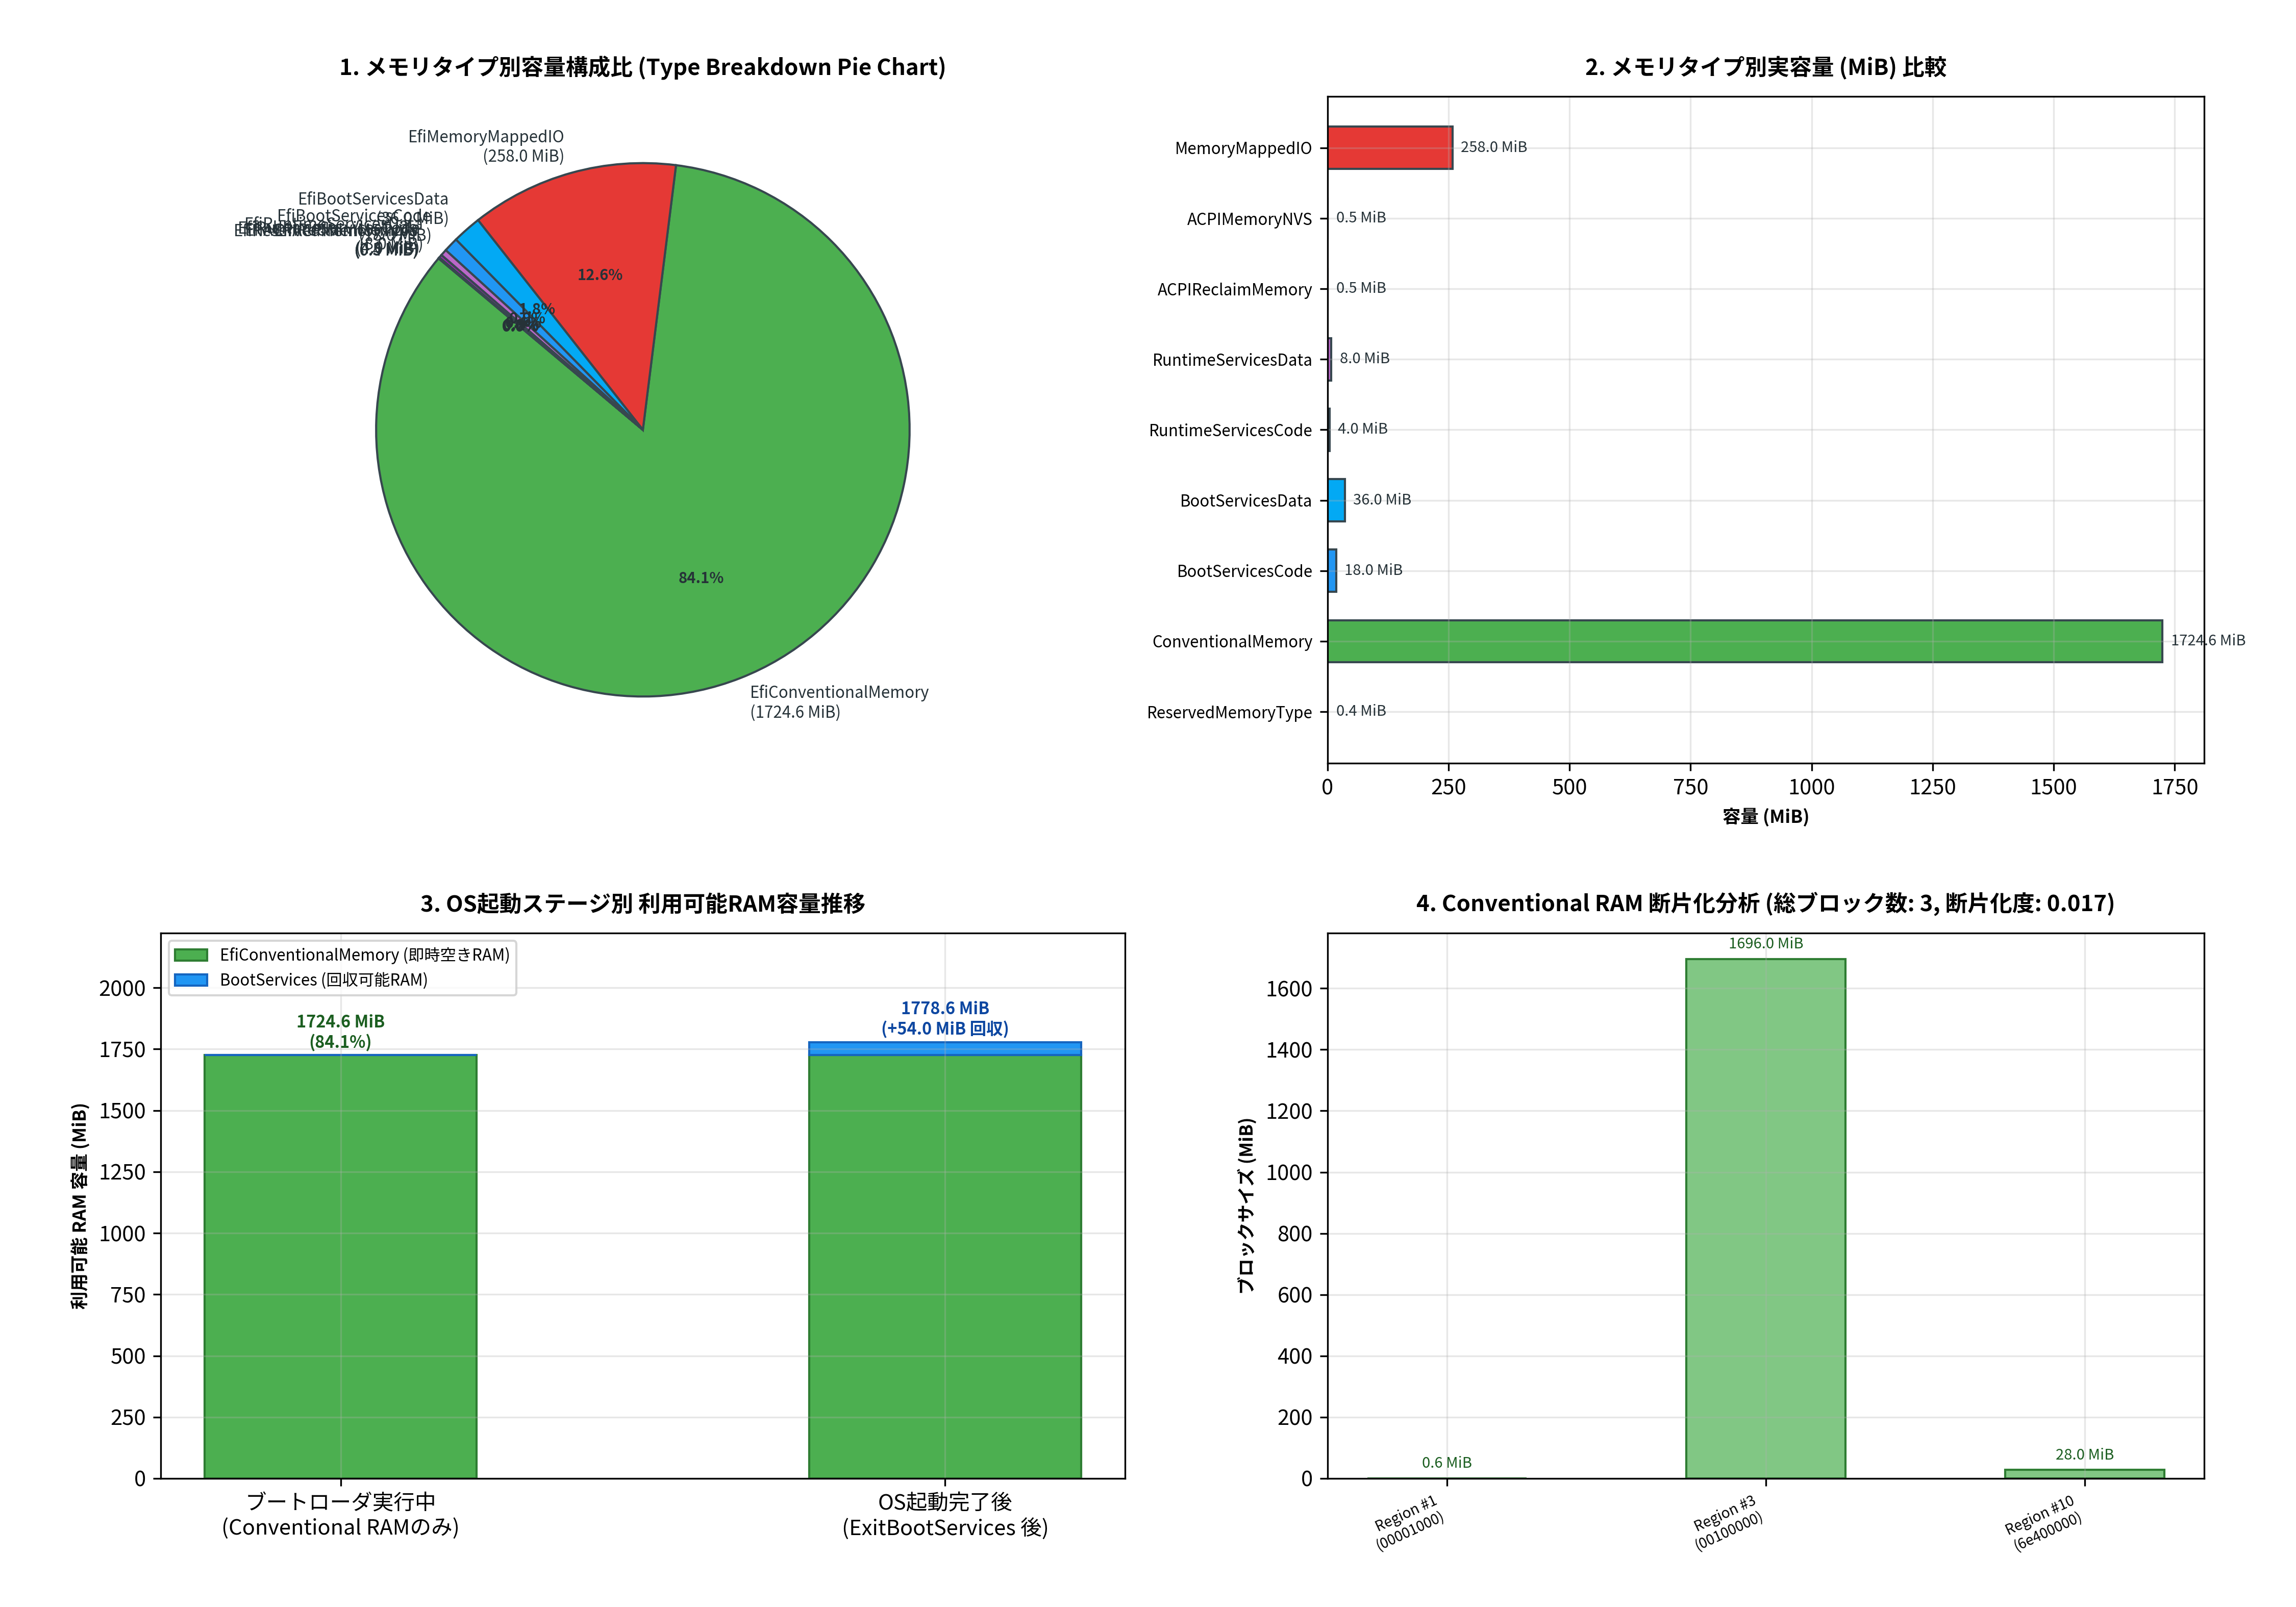

In [2]:
# 高解像度図版 Figure 2.13 の生成と表示
from common.os_sim import MemoryMapAnalyzer, plot_memory_map_analysis
from IPython.display import Image, display

sample_csv = MemoryMapAnalyzer.create_sample_qemu_memmap_csv(total_ram_gib=2.0)
analyzer = MemoryMapAnalyzer.from_csv(sample_csv)

fig13_path = plot_memory_map_analysis(analyzer, "result/fig2_13_memory_map_analysis_breakdown.png")
display(Image(filename=fig13_path))


## 2.7.6 物理アドレス空間のレイアウトと断片化（Fragmentation）の観察

メモリマップの CSV を先頭アドレス（`PhysicalStart`）順に並べ替えて観察すると、物理メモリが一続きの広大な板ではなく、**細かく分断（断片化 / Fragmentation）されている** ことが分かります。

```mermaid
flowchart LR
    subgraph LowMem["0x00000000 〜 0x00100000 (低位 1MiB 領域)"]
        direction TB
        L0["0x0000: 割込ベクタ・BDA (Reserved)"]
        L1["0x1000: 低位空きRAM (Conventional ~636KiB)"]
        L2["0x9F000: EBDA (Reserved)"]
        L3["0xA0000: VRAM (128KiB Reserved)"]
        L4["0xC0000: ROM (256KiB Reserved)"]
    end

    subgraph HighMem["0x00100000 〜 (高位メモリ領域)"]
        direction TB
        H1["0x00100000 (1MiB): 主記憶RAM (Conventional 数百MiB〜数GiB)"]
        H2["ファームウェア・BootServices (Code / Data)"]
        H3["ACPI テーブル・RuntimeServices"]
    end

    subgraph MMIOHole["0x80000000 / 0xE0000000 〜 0x100000000 (3.5GiB〜4GiB)"]
        direction TB
        M1["PCI Express Configuration Space"]
        M2["Local APIC / I/O APIC MMIO"]
        M3["マザーボードチップセット制御レジスタ"]
    end

    LowMem --> HighMem --> MMIOHole
```

### 1. 低位 1MiB 領域（Low Memory / Real Mode Legacy Space）
アドレス `0x00000000` から `0x00100000`（1MiB）までは、IBM PC/AT 互換機の長い歴史的制約を色濃く残しています：
- `0x00000000` 〜 `0x00001000` (4KiB): CPU リアルモード割り込みベクタ表（IVT: *Interrupt Vector Table*）や BIOS データエリア（BDA: *BIOS Data Area*）が存在するため `EfiReservedMemoryType`。
- `0x00001000` 〜 `0x0009F000` (~636KiB): MS-DOS 時代に「基本メモリ（Conventional Memory 640KB）」と呼ばれた領域。UEFI でも `EfiConventionalMemory` として空いています。
- `0x0009F000` 〜 `0x00100000` (384KiB): 拡張 BIOS データ領域（EBDA）、VRAM（VGAテキスト画面・グラフィックス）、および ROM 領域として予約（Reserved）。

### 2. 高位メモリ領域（1MiB 以降: High Memory）
アドレス `0x00100000`（1MiB）以降が、現代の 64 ビット OS にとっての**主戦場となる巨大な物理 RAM** です。
- 通常、1MiB の直後から数百 MiB 〜 数 GiB に及ぶ最大の連続 `EfiConventionalMemory` ブロックが広がります。
- **MikanOS カーネルの配置場所**: 次章（第3章）で解説するように、ブートローダは ELF 形式のカーネルを物理アドレス **`0x00100000`（1MiB）** へと読み込みます。このアドレスは低位予約領域の直後に位置し、広大な連続空き RAM の先頭であるため、歴史的・技術的に極めて安全で標準的な配置場所なのです。

### 3. 32ビット境界の PCI MMIO ホール（MMIO Hole at 3.5GiB〜4GiB）
32ビット物理アドレスの限界である 4GiB（`0x100000000`）の手前（`0x80000000` または `0xE0000000` 付近）には、マザーボードや PCI デバイスのための広大な予約・MMIO 領域（`EfiMemoryMappedIO`）が配置されます。
4GiB 以上の物理 RAM を搭載したマシンでは、この MMIO ホールによって押し出された物理 RAM が **4GiB 以降の 64 ビット高位アドレス空間** に再マッピング（Memory Remap）されて配置されます。


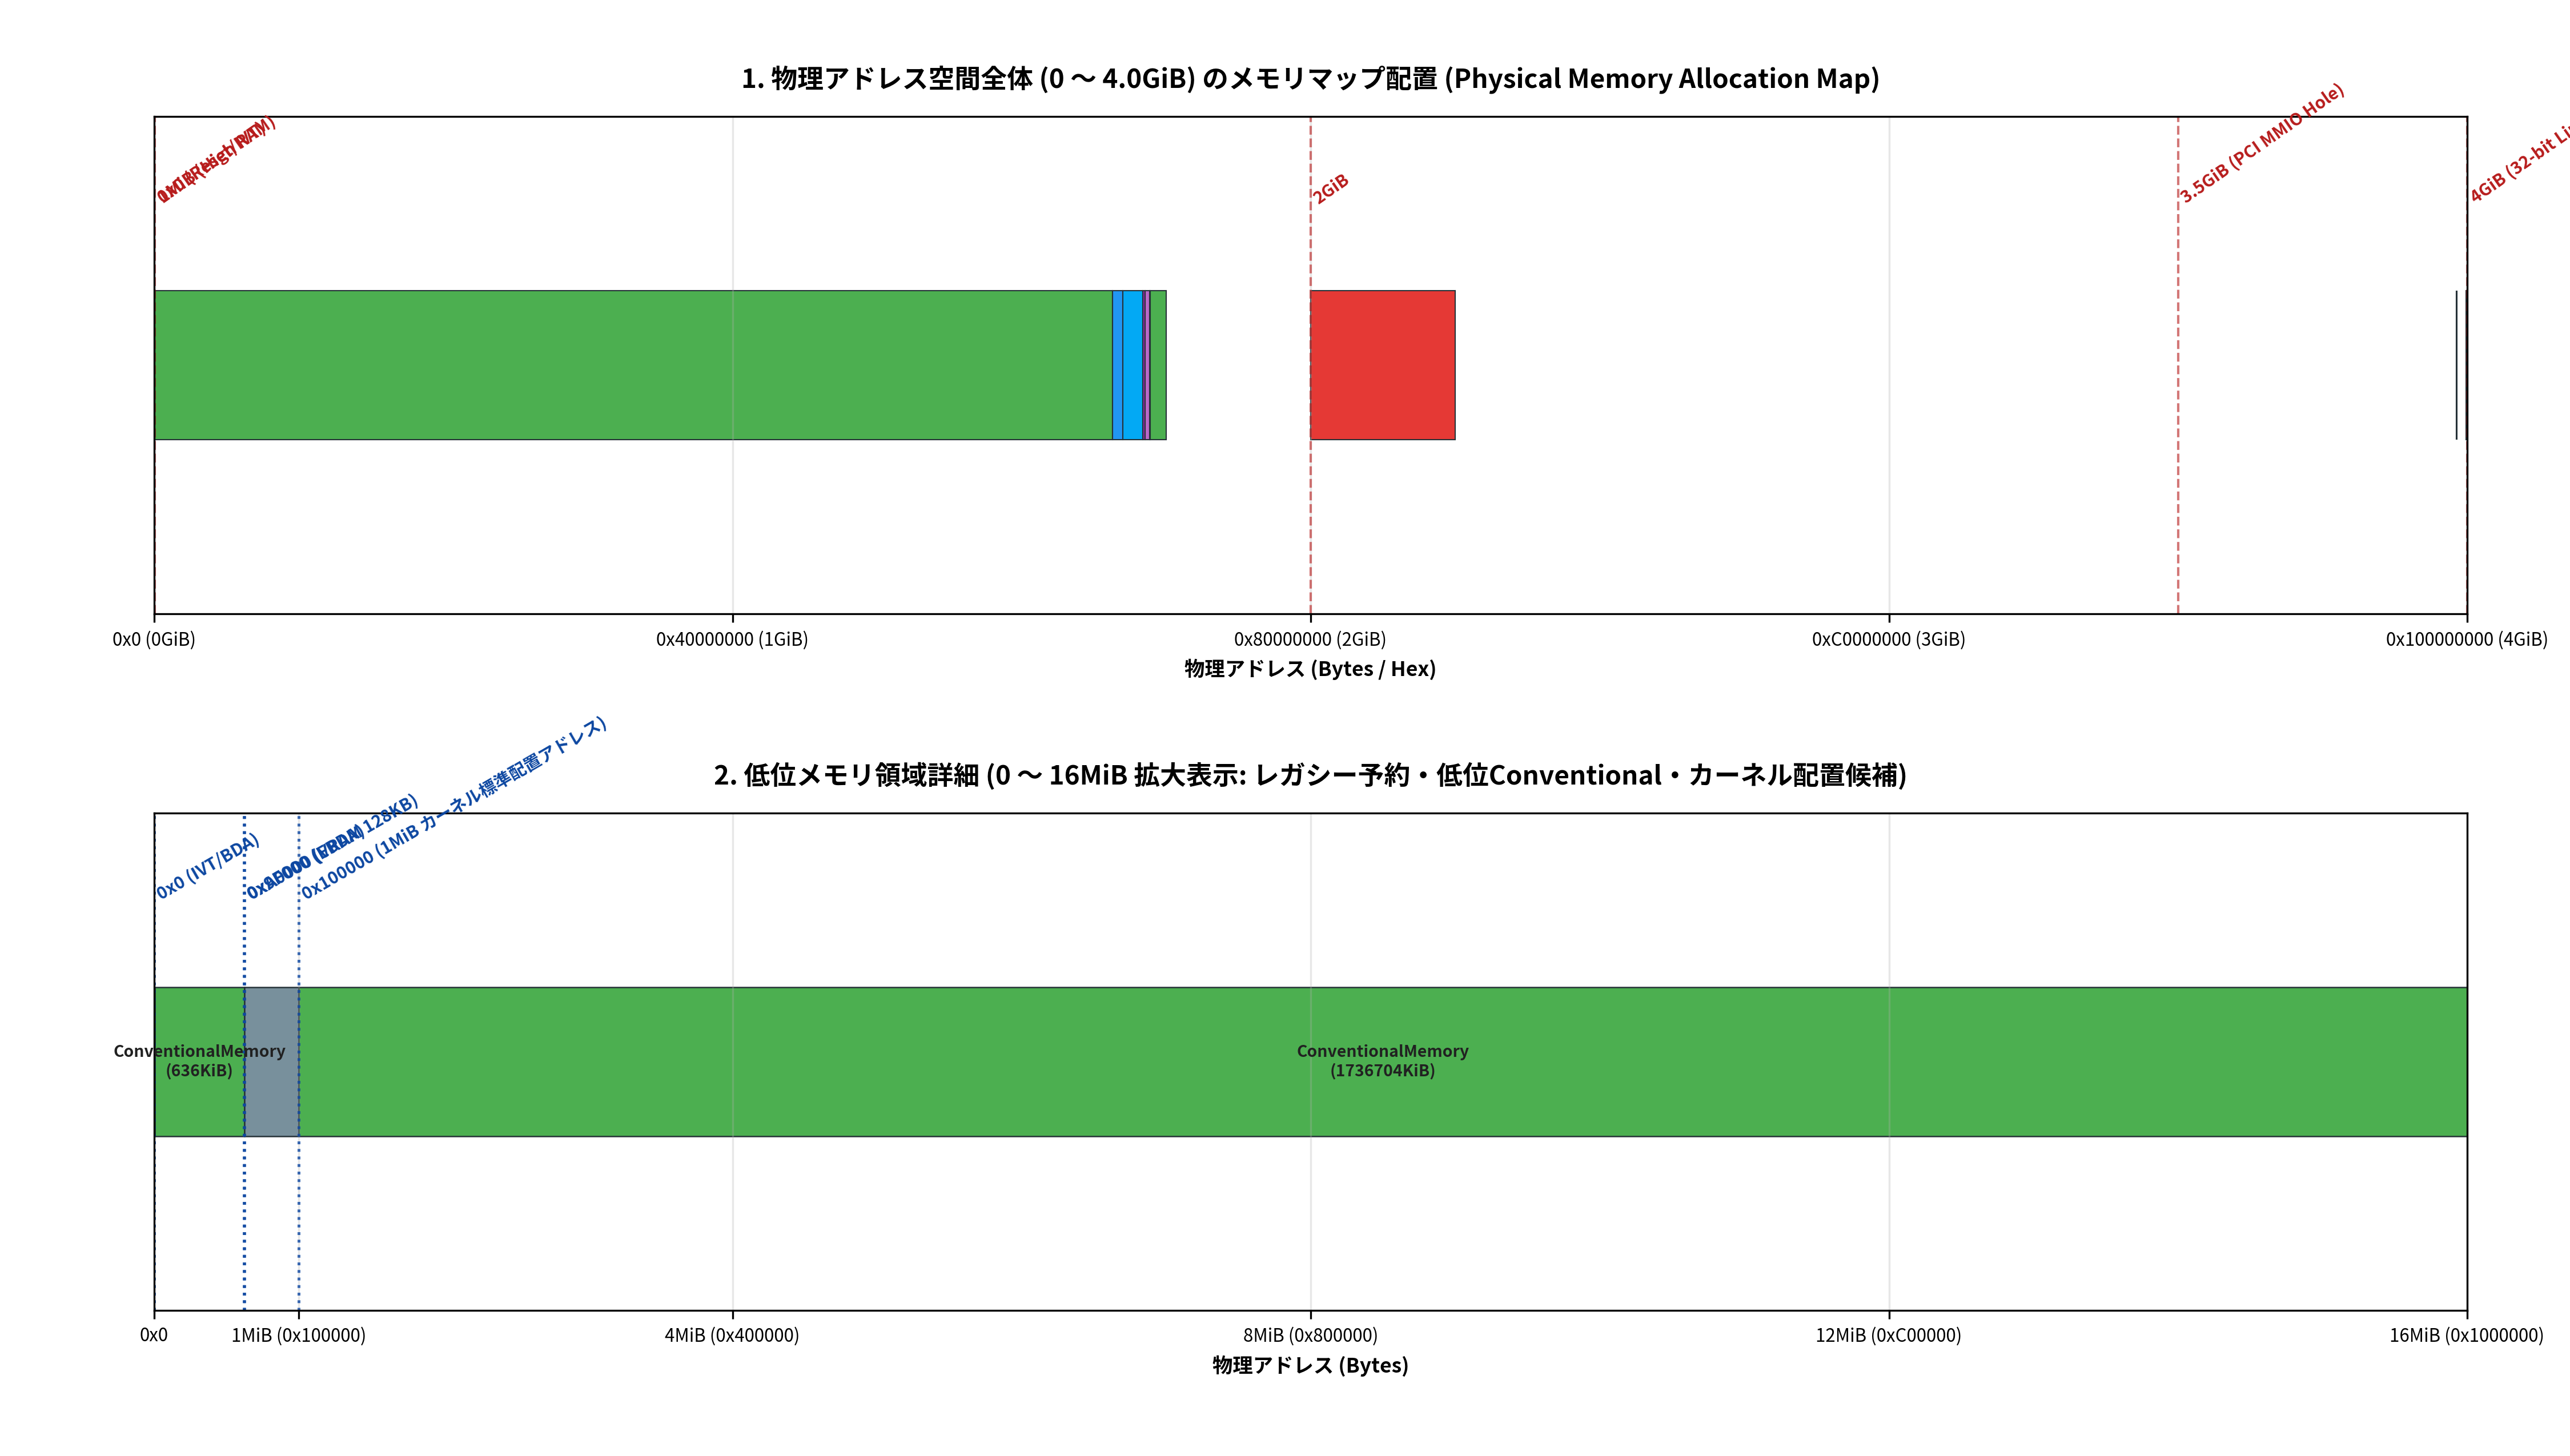

In [3]:
# 高解像度図版 Figure 2.14 の生成と表示
from common.os_sim import MemoryMapAnalyzer, plot_physical_memory_layout_map
from IPython.display import Image, display

sample_csv = MemoryMapAnalyzer.create_sample_qemu_memmap_csv(total_ram_gib=2.0)
analyzer = MemoryMapAnalyzer.from_csv(sample_csv)

fig14_path = plot_physical_memory_layout_map(analyzer, "result/fig2_14_physical_memory_layout_map.png")
display(Image(filename=fig14_path))


## 2.7.8 Python によるメモリマップ CSV パース・統計解析の対話型シミュレーション

`common/os_sim.py` に実装された `MemoryMapAnalyzer` クラスを使用して、出力されたメモリマップ CSV のパース、タイプ別集計、空き Conventional メモリ計算、回収可能 BootServices 計算、断片化指標、およびカーネル配置候補領域の探索を対話的に実証します。


In [4]:
# Python によるメモリマップ CSV 解析と統計メトリクス検証
from common.os_sim import MemoryMapAnalyzer

# 1. 2GiB 構成の QEMU OVMF メモリマップ CSV サンプルの生成とパース
sample_csv = MemoryMapAnalyzer.create_sample_qemu_memmap_csv(total_ram_gib=2.0)
analyzer = MemoryMapAnalyzer.from_csv(sample_csv)

print("=== メモリマップ要約テーブル (Memory Map Summary Table) ===")
print(analyzer.summary_table())

# 2. 空き Conventional メモリの分析
conv = analyzer.conventional_memory_summary()
print("\n=== 即時利用可能 Conventional RAM (Type 7) ===")
print(f"エントリ数: {conv['record_count']} 箇所")
print(f"合計ページ数: {conv['pages']} pages")
print(f"合計容量: {conv['mib']:.2f} MiB ({conv['gib']:.3f} GiB)")
print(f"全体比率: {conv['percentage']:.2f} %")
max_blk = conv['max_block']
print(f"最大連続ブロック: 物理アドレス 0x{max_blk['PhysicalStart']:08x} 〜 0x{max_blk['PhysicalEnd']:08x} ({max_blk['SizeMiB']:.2f} MiB)")

# 3. 回収可能 Boot Services メモリの分析
bs = analyzer.reclaimable_boot_services_summary()
post_boot = analyzer.available_memory_after_boot()
print("\n=== OS起動後 (ExitBootServices後) の回収可能メモリ ===")
print(f"回収可能 Boot Services: {bs['mib']:.2f} MiB ({bs['pages']} pages)")
print(f"OS起動後の最終利用可能 RAM: {post_boot['mib']:.2f} MiB ({post_boot['percentage']:.2f} %)")

# 4. 断片化指標とカーネル配置候補領域 (>= 16MiB)
frag = analyzer.fragmentation_metrics()
print("\n=== メモリ断片化指標 (Fragmentation Metrics) ===")
print(f"ブロック数: {frag['num_blocks']}")
print(f"平均ブロックサイズ: {frag['avg_block_mib']:.2f} MiB")
print(f"最大ブロック占有率: {frag['largest_block_ratio']*100:.2f} %")
print(f"断片化指数: {frag['fragmentation_index']:.4f} (0.0=連続, 1.0=極度に分断)")

kernel_candidates = analyzer.find_free_regions_above(16 * 1024 * 1024)
print(f"\nカーネル配置可能領域 (>= 16 MiB): {len(kernel_candidates)} 箇所")
for c in kernel_candidates:
    print(f"  - 0x{c['PhysicalStart']:08x} 〜 0x{c['PhysicalEnd']:08x} ({c['SizeMiB']:.2f} MiB)")


=== メモリマップ要約テーブル (Memory Map Summary Table) ===
Type (Name)                  | Count |      Pages | Size (MiB) | Ratio (%)
------------------------------------------------------------------------
EfiConventionalMemory        |     3 |     441503 |    1724.62 |    84.13%
EfiMemoryMappedIO            |     4 |      66050 |     258.01 |    12.59%
EfiBootServicesData          |     1 |       9216 |      36.00 |     1.76%
EfiBootServicesCode          |     1 |       4608 |      18.00 |     0.88%
EfiRuntimeServicesData       |     1 |       2048 |       8.00 |     0.39%
EfiRuntimeServicesCode       |     1 |       1024 |       4.00 |     0.20%
EfiACPIReclaimMemory         |     1 |        128 |       0.50 |     0.02%
EfiACPIMemoryNVS             |     1 |        128 |       0.50 |     0.02%
EfiReservedMemoryType        |     2 |         97 |       0.38 |     0.02%
------------------------------------------------------------------------
TOTAL                        |    15 |     524802 |    2

## 2.7.9 C++20 ホスト側メモリマップ解析エンジンの対話型コンパイル＆実行

ホスト側環境（Linux / WSL / Colab）において、標準 C++20 で実装されたスタンドアロンメモリマップ解析エンジン（`src/ch02/analyze_memory_map_sim.cpp`）をコンパイルし、CSV のパーサ、数値変換、メモリ集計、断片化計算、および MMIO ホール検出の単体テストを実行します。


In [5]:
# C++20 スタンドアロンメモリマップ解析エンジンのビルドと実行
import subprocess
from pathlib import Path

cpp_src = Path("../src/ch02/analyze_memory_map_sim.cpp")
if not cpp_src.exists():
    cpp_src = Path("src/ch02/analyze_memory_map_sim.cpp")

bin_path = Path("/tmp/ch02_analyze_memory_map_sim")

print(f"C++20 ソースコード: {cpp_src}")
cmd_compile = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", str(cpp_src), "-o", str(bin_path)]
res_compile = subprocess.run(cmd_compile, capture_output=True, text=True)

if res_compile.returncode != 0:
    print("コンパイルエラー:\n", res_compile.stderr)
else:
    print("コンパイル成功！実行中...\n")
    res_run = subprocess.run([str(bin_path)], capture_output=True, text=True)
    print(res_run.stdout)


C++20 ソースコード: ../src/ch02/analyze_memory_map_sim.cpp


コンパイル成功！実行中...

MikanOS Chapter 2.7: UEFI Memory Map Output Analysis C++20 Verification
[Test 1] Testing MemoryMap CSV parsing and field deserialization...
  -> Total Descriptors: 7, Total Memory: 2080.06 MiB (2.03 GiB)
  [PASS] CSV parsing and numeric conversion verified.
[Test 2] Testing memory type breakdown and usable RAM calculation...
  -> Immediately Usable Conventional RAM: 1792.62 MiB
  -> Reclaimable Boot Services RAM: 96.00 MiB
  -> Total Available RAM after ExitBootServices: 1888.62 MiB
  [PASS] Usable RAM and post-boot reclaimability verified.
[Test 3] Testing fragmentation metrics and MMIO gap detection...
  -> Fragmentation Index: 0.33 (Blocks: 3)
  -> Detected Address Gaps: 2 (First gap: 10100000 - 20000000 (255.00 MiB))
  [PASS] Fragmentation and gap analysis verified.

All Section 2.7 C++20 verifications passed successfully!



## 2.7.10 MikanOS におけるメモリマップの将来活用（第3章・第8章への伏線）

本節で確認したメモリマップは、ただ「眺めて納得する」だけのものではありません。今後の MikanOS 実装において、OS の心臓部を支える以下の重要局面で直接活用されます。

```mermaid
flowchart TD
    subgraph Day02["第2章: 本節 (day02b)"]
        SaveCSV["メモリマップの取得と CSV 出力 (GetMemoryMap / SaveMemoryMap)"]
    end

    subgraph Day03["第3章: 初めてのカーネル (day03a〜03c)"]
        LoadKernel["カーネル ELF の読み込み (0x00100000 へのロード)"]
        CheckSpace["メモリマップを参照し、0x100000 が広大な空きRAMであることを確認して配置"]
    end

    subgraph Day08["第8章: メモリ管理 (day08a〜08c)"]
        PassMap["ブートローダからカーネルへの MemoryMap 構造体引き渡し"]
        ExitBS["ExitBootServices() 呼び出しによる BootServices 領域の回収"]
        BitmapMgr["BitmapMemoryManager による 4KiB ページ単位のビットマップ管理初期化"]
    end

    SaveCSV --> CheckSpace --> LoadKernel
    SaveCSV --> PassMap --> ExitBS --> BitmapMgr
```

1. **第3章: カーネルのメモリロード先アドレス（`0x00100000`）の決定**:
   - ブートローダは、FAT ファイルシステムから `kernel.elf` を読み込み、物理アドレス `0x100000`（1MiB）に配置します。本節の分析で実証した通り、このアドレスは低位予約領域（IVT/BDA/EBDA/VRAM）を安全に回避し、数十〜数千 MiB に及ぶ最大の連続 `EfiConventionalMemory` の先頭アドレスです。
2. **第8章: カーネル独自メモリ管理（`BitmapMemoryManager`）の構築**:
   - 第8章では、ブートローダが取得したメモリマップを構造体ポインタ経由でカーネルの `KernelMain()` 引数として引き渡します。
   - カーネルはメモリマップを1行ずつ走査し、`EfiConventionalMemory` および `ExitBootServices` 後に空いた `EfiBootServicesCode/Data` のフレームを、4KiB ごとに 1ビットのフラグで表す **ビットマップ配列（`BitmapMemoryManager`）** に「空き」として登録します。これにより、カーネル内での `malloc()` や `new`、ページテーブル割り当てがすべて可能になるのです。


## 2.7.11 理解度確認クイズ（自己採点形式）

本節で学んだ UEFI メモリマップの構造、各メモリタイプの役割、利用可能 RAM の計算、およびメモリレイアウトの重要概念を定着させるためのクイズです。下のセルを実行して自己採点を行ってください。


In [6]:
# 理解度確認クイズ（assert による自己検証）
def test_section_2_7_quiz():
    # [Q1] UEFI メモリマップにおいて、OS がブート中から汎用 RAM として即座に使用できるメモリタイプはどれか？
    # 1: EfiReservedMemoryType
    # 2: EfiConventionalMemory
    # 3: EfiMemoryMappedIO
    # 4: EfiRuntimeServicesData
    answer_q1 = 2
    assert answer_q1 == 2, "Q1 不正解: 通常の空き物理RAMを表すのは Type 7 の EfiConventionalMemory です。"

    # [Q2] gBS->ExitBootServices() 呼び出し後に、OS が空き RAM プールとして回収・再利用可能なメモリタイプはどれか？
    # 1: EfiRuntimeServicesCode & EfiRuntimeServicesData
    # 2: EfiACPIMemoryNVS & EfiMemoryMappedIO
    # 3: EfiBootServicesCode & EfiBootServicesData
    # 4: EfiReservedMemoryType & EfiPalCode
    answer_q2 = 3
    assert answer_q2 == 3, "Q2 不正解: ブートサービス終了後は BootServicesCode/Data (Type 3/4) が回収可能です。"

    # [Q3] あるメモリディスクリプタの PhysicalStart が 0x00100000, NumberOfPages が 0x1000 (16進数) であるとき、
    # 当該領域の容量は何 MiB か？
    # 0x1000 = 4096 ページ。1ページ = 4096 バイト。
    # 4096 * 4096 = 16,777,216 バイト = 16 MiB。
    answer_q3_mib = 16
    assert answer_q3_mib == 16, "Q3 不正解: 0x1000 ページ = 4096 ページ * 4096 バイト = 16 MiB です。"

    # [Q4] MikanOS が第3章でカーネルを読み込む標準物理アドレス 0x00100000 (1MiB) を採用する主な理由はどれか？
    # 1: 0x0〜1MiB のレガシー予約領域を回避し、最大の連続空き Conventional RAM の先頭であるため
    # 2: 32ビット MMIO ホールがその位置に存在するため
    # 3: UEFI ファームウェアが 0x100000 以外のメモリアクセスをハードウェア的に禁止しているため
    # 4: ACPI テーブルが常に 0x100000 に配置されているため
    answer_q4 = 1
    assert answer_q4 == 1, "Q4 不正解: 低位 1MiB の予約領域を回避した連続空き RAM の先頭であるためです。"

    print("🎉 すべてのクイズに正解しました！第2章 2.7節「メモリマップの確認」の完全制覇です！")

test_section_2_7_quiz()


🎉 すべてのクイズに正解しました！第2章 2.7節「メモリマップの確認」の完全制覇です！
